Persius's first satire has always struck me as an especially *negative* poem. Not just in tone—the whole thing drips with contempt for contemporary literary culture—but in the nuts-and-bolts diction. It feels like every other clause is built on a negation: *non*, *nec*, *neque*. Is that actually true? And if so, how does Persius compare to the other Roman satirists?

To test this, we can count the rate of negative words per 1,000 words across all the satires of Persius, Horace, and Juvenal. Rather than picking negation words by intuition, we derive our word list from the [Universal Dependencies](https://universaldependencies.org/) Latin treebanks: every word form annotated with the `advmod:neg` dependency relation across all available Latin UD treebanks. This gives us a principled, corpus-derived vocabulary of negative particles.

**NB**: This is an updated version of a [notebook](https://github.com/diyclassics/ll-experiments) I originally wrote in November 2017 using CLTK. The code below has been rewritten to use [LatinCy](https://huggingface.co/latincy) and the [`latincyreaders`](https://github.com/diyclassics/latincy-readers) package. The sections on the corpus-wide baseline and the dispersion plot for Persius are new for this version.

## Setup

In [1]:
import re
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from latincyreaders import TesseraeReader

T = TesseraeReader()

# Negative word forms derived from advmod:neg annotations
# across all Latin Universal Dependencies treebanks
NEGATIVE_WORDS = {
    'non', 'nec', 'neque',  # core negators
    'haud', 'haut',          # emphatic negation
    'ne',                     # prohibitive/subjunctive negation
    'ni',                     # archaic conditional negation
    'nunquam', 'numquam',    # "never" (spelling variants)
    'nondum',                 # "not yet"
    'nihil', 'nichil',       # "nothing" (spelling variants)
}

print(f'{len(NEGATIVE_WORDS)} negative word forms (from UD advmod:neg)')

12 negative word forms (from UD advmod:neg)


## Loading and splitting the texts

The Tesserae corpus stores each text with line-level citation tags, e.g. `<pers. sat. 1.5>` for Persius Satire 1, line 5. We can parse these tags to split each poet’s output into individual satires.

In [2]:
def split_by_satire(filepath, citation_pattern, label_fn):
    """Read a Tesserae file and split it into individual poems by citation."""
    satires = defaultdict(list)
    with open(filepath) as f:
        for line in f:
            match = re.match(citation_pattern, line)
            if match:
                label = label_fn(match)
                text = line[match.end():].strip()
                satires[label].append(text)
    return {label: ' '.join(lines) for label, lines in satires.items()}

In [3]:
tess_dir = T.root

# Persius: <pers. sat. X.Y>
persius = split_by_satire(
    tess_dir / 'persius.satires.tess',
    r'<pers\. sat\. (\d+)\.\d+>\s*',
    lambda m: f'Persius Satire {m.group(1)}'
)

# Horace: <hor. s. B.S.L>
horace = split_by_satire(
    tess_dir / 'horace.satires.part.1.tess',
    r'<hor\. s\. 1\.(\d+)\.\d+>\s*',
    lambda m: f'Horace Satire 1.{m.group(1)}'
)
horace.update(split_by_satire(
    tess_dir / 'horace.satires.part.2.tess',
    r'<hor\. s\. 2\.(\d+)\.\d+>\s*',
    lambda m: f'Horace Satire 2.{m.group(1)}'
))

# Juvenal: <juv. X.Y>
juvenal = split_by_satire(
    tess_dir / 'juvenal.satires.tess',
    r'<juv\. (\d+)\.\d+>\s*',
    lambda m: f'Juvenal Satire {m.group(1)}'
)

print(f'Persius: {len(persius)} poems')
print(f'Horace: {len(horace)} poems')
print(f'Juvenal: {len(juvenal)} poems')

Persius: 6 poems
Horace: 18 poems
Juvenal: 16 poems


## Counting negative diction

Our negative word list comes from the `advmod:neg` dependency relation in the Latin UD treebanks—every word form annotated as a negative adverbial modifier across all available treebanks. This gives us 12 forms covering the core negators (*non*, *nec*, *neque*), emphatic and prohibitive negation (*haud*, *ne*), temporal negation (*nondum*, *nunquam*), and negative pronouns used adverbially (*nihil*). For each satire, we tokenize with LatinCy and count how many of these words appear per 1,000 tokens.

In [4]:
import spacy

nlp = spacy.load('la_core_web_lg')

def measure_negation(poems: dict) -> list:
    """Return list of (title, rate_per_1000, neg_count, total_count) tuples."""
    results = []
    for title, text in poems.items():
        doc = nlp(text)
        tokens = [t for t in doc if t.is_alpha]
        total = len(tokens)
        neg_count = sum(1 for t in tokens if t.text.lower() in NEGATIVE_WORDS)
        rate = round((1000 * neg_count) / total, 2) if total else 0
        results.append((title, rate, neg_count, total))
    return results

In [5]:
persius_results = measure_negation(persius)
horace_results = measure_negation(horace)
juvenal_results = measure_negation(juvenal)

all_results = horace_results + persius_results + juvenal_results

df = pd.DataFrame(all_results, columns=['Satire', 'Rate per 1,000', 'Negative words', 'Total words'])
df = df.sort_values('Rate per 1,000', ascending=False).reset_index(drop=True)
df.index = df.index + 1
df.index.name = 'Rank'
df

,Satire,"Rate per 1,000",Negative words,Total words
Rank,,,,
1,Persius Satire 1,36.38,33,907
2,Horace Satire 1.1,31.63,26,822
3,Horace Satire 1.2,27.96,26,930
4,Horace Satire 1.6,27.59,25,906
5,Juvenal Satire 13,26.28,43,1636
6,Horace Satire 2.1,26.00,15,577
7,Horace Satire 2.7,25.16,20,795
8,Horace Satire 1.9,25.00,13,520
9,Juvenal Satire 16,23.38,9,385


## Visualizing the results

A bar chart makes the comparison across all three satirists immediately legible.

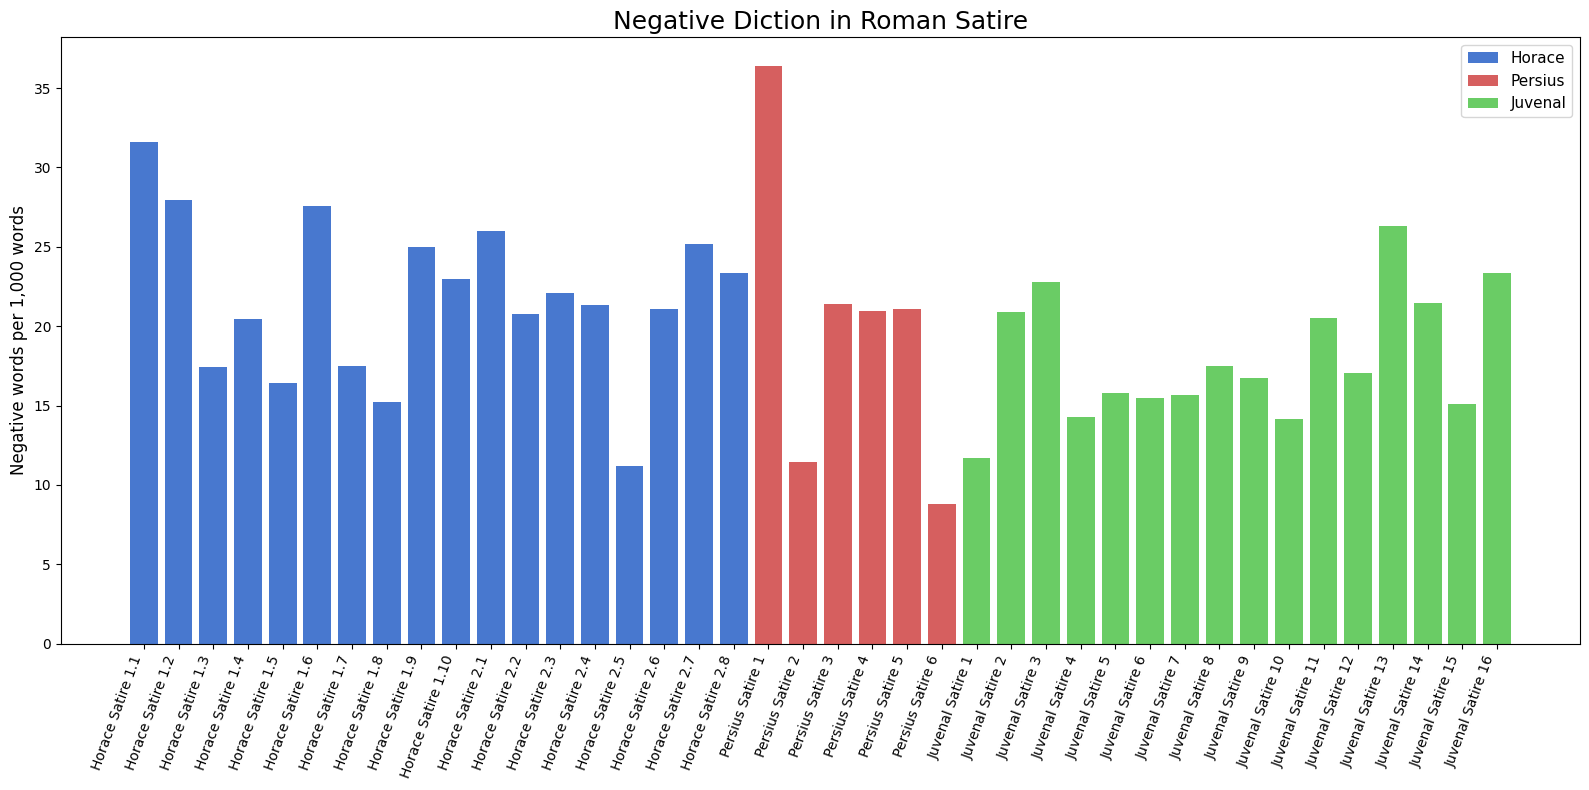

In [6]:
titles = [r[0] for r in all_results]
rates = [r[1] for r in all_results]

colors = []
for t in titles:
    if t.startswith('Horace'):
        colors.append('#4878CF')
    elif t.startswith('Persius'):
        colors.append('#D65F5F')
    else:
        colors.append('#6ACC65')

fig, ax = plt.subplots(figsize=(16, 8))
x_pos = np.arange(len(titles))
bars = ax.bar(x_pos, rates, color=colors)

ax.set_xticks(x_pos)
ax.set_xticklabels(titles, rotation=70, ha='right', fontsize=10)
ax.set_ylabel('Negative words per 1,000 words', fontsize=12)
ax.set_title('Negative Diction in Roman Satire', fontsize=18)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4878CF', label='Horace'),
    Patch(facecolor='#D65F5F', label='Persius'),
    Patch(facecolor='#6ACC65', label='Juvenal'),
]
ax.legend(handles=legend_elements, fontsize=11)

plt.tight_layout()
plt.show()

## How negative is Latin verse in general?

The comparison above is limited to satire. But is satire even a particularly negative genre? The [`latincyreaders`](https://github.com/diyclassics/latincy-readers) package provides metadata for each text in the Tesserae corpus, including its genre and mode (prose/verse). We can compute the same negation rate for every verse text in the corpus and compare by genre. For satire, we split each poet's collected works into individual poems so that we get one data point per satire rather than one per file. All texts—whether whole files or individual poems—are filtered by the same minimum word count (225 words, roughly the length of the shortest satire). Since we are only counting specific word forms, we can skip the full NLP pipeline and work directly with raw text.

In [7]:
def measure_negation_raw(text, min_words=225):
    """Fast negation rate using raw text splitting (no NLP model needed)."""
    words = re.findall(r'[a-zA-Z]+', text.lower())
    total = len(words)
    if total < min_words:
        return None
    neg = sum(1 for w in words if w in NEGATIVE_WORDS)
    return round(1000 * neg / total, 2)

meta_lookup = {fid: m for fid, m in T.metadata()}
verse_fids = [fid for fid, m in meta_lookup.items() if m.get('mode') == 'verse']

genre_rates = defaultdict(list)

# For satire files, split into individual poems before measuring
all_satires = {}
all_satires.update(persius)
all_satires.update(horace)
all_satires.update(juvenal)

for fid in verse_fids:
    genre = meta_lookup[fid]['genre']
    if genre == 'satire':
        continue  # handle satire separately below
    text = list(T.texts(fileids=[fid]))[0]
    rate = measure_negation_raw(text)
    if rate is not None:
        genre_rates[genre].append(rate)

# Add individual satires with the same min_words threshold
for label, text in all_satires.items():
    rate = measure_negation_raw(text)
    if rate is not None:
        genre_rates['satire'].append(rate)

print(f'Computed negation rates for {sum(len(v) for v in genre_rates.values())} verse texts across {len(genre_rates)} genres (min. 225 words)')
print(f'  Satire: {len(genre_rates["satire"])} individual poems (of {len(all_satires)} total)')

Computed negation rates for 304 verse texts across 8 genres (min. 225 words)
  Satire: 40 individual poems (of 40 total)


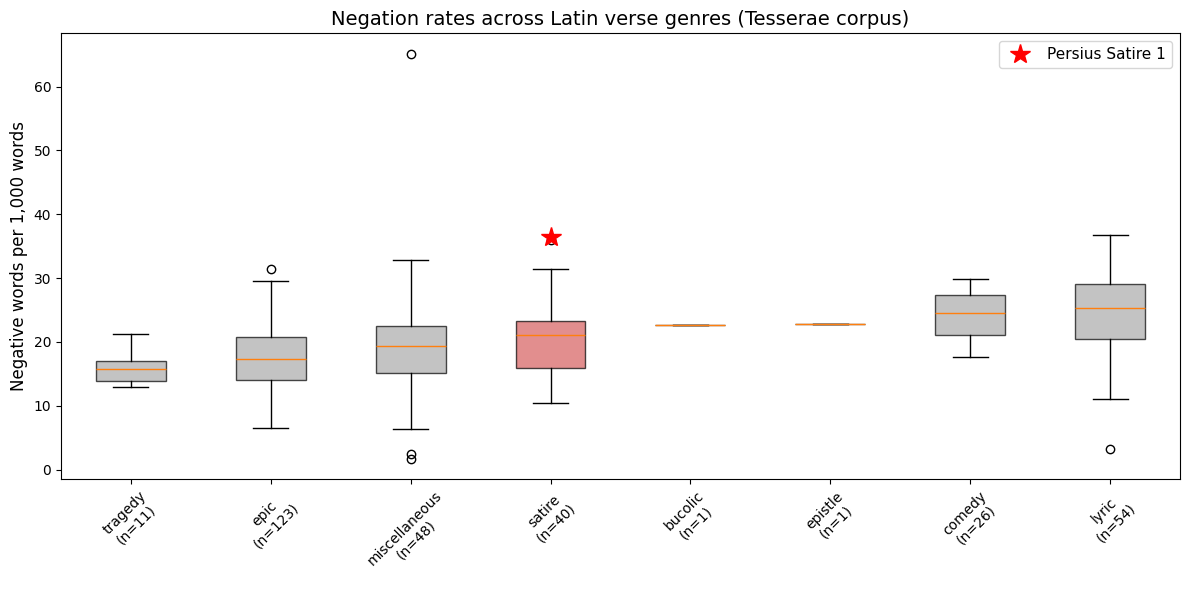

In [8]:
genre_order = sorted(genre_rates.keys(), key=lambda g: np.median(genre_rates[g]))
data_for_plot = [genre_rates[g] for g in genre_order]
tick_labels = [f'{g}\n(n={len(genre_rates[g])})' for g in genre_order]

fig, ax = plt.subplots(figsize=(12, 6))
bp = ax.boxplot(data_for_plot, tick_labels=tick_labels, patch_artist=True, vert=True)

for i, genre in enumerate(genre_order):
    color = '#D65F5F' if genre == 'satire' else '#AAAAAA'
    bp['boxes'][i].set_facecolor(color)
    bp['boxes'][i].set_alpha(0.7)

# Mark Persius 1 with a star
persius_1_rate = next(r[1] for r in persius_results if 'Satire 1' in r[0])
satire_idx = genre_order.index('satire') + 1
ax.plot(satire_idx, persius_1_rate, 'r*', markersize=15, zorder=5, label='Persius Satire 1')

ax.set_ylabel('Negative words per 1,000 words', fontsize=12)
ax.set_title('Negation rates across Latin verse genres (Tesserae corpus)', fontsize=14)
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Where does the negativity fall?

Knowing *how much* negative diction each satire contains is one thing; knowing *where* it clusters is another. A dispersion plot shows the position of each negation (*non*, *nec*, or *neque*) as a percentage of the poem's length, letting us compare the distribution across all six of Persius's satires. Is the negativity frontloaded? Concentrated in one passage? Or spread throughout?

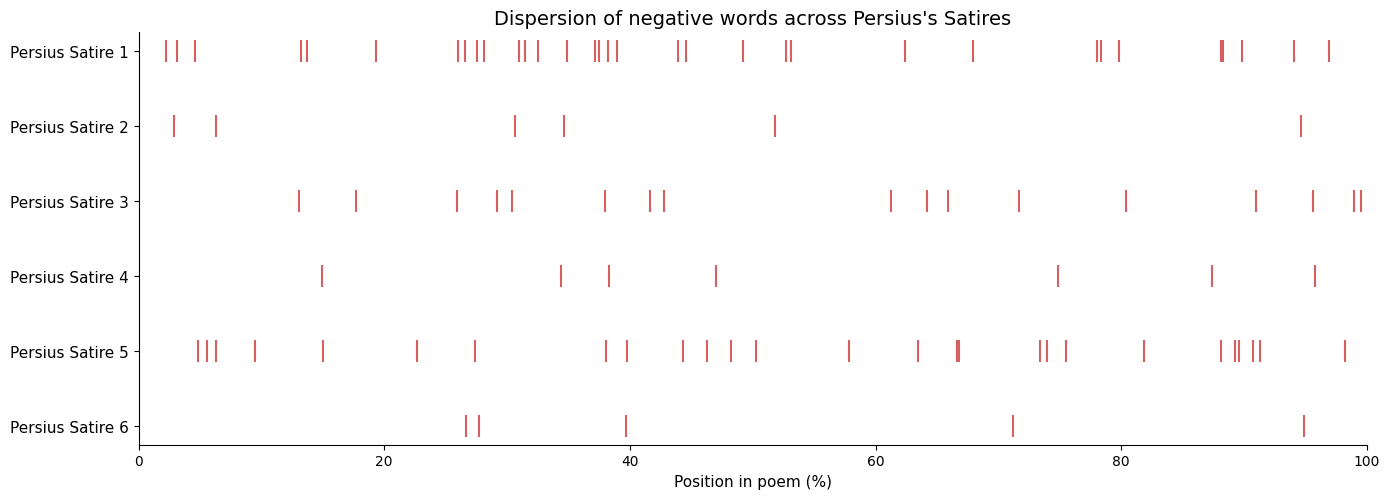

In [9]:
satire_labels = list(persius.keys())
n_satires = len(satire_labels)

fig, ax = plt.subplots(figsize=(14, 0.6 * n_satires + 1.5))

for row, label in enumerate(reversed(satire_labels)):
    text = persius[label]
    doc = nlp(text)
    alpha_tokens = [t for t in doc if t.is_alpha]
    total = len(alpha_tokens)
    y = row + 1

    for i, t in enumerate(alpha_tokens):
        if t.text.lower() in NEGATIVE_WORDS:
            pos = 100 * i / total
            ax.plot(pos, y, '|', color='#D65F5F', markersize=16, markeredgewidth=1.5)

ax.set_yticks(range(1, n_satires + 1))
ax.set_yticklabels(list(reversed(satire_labels)), fontsize=11)
ax.set_xlim(0, 100)
ax.set_xlabel('Position in poem (%)', fontsize=11)
ax.set_title('Dispersion of negative words across Persius\'s Satires', fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## Discussion

Using a principled word list derived from UD treebank annotations—rather than a hand-picked set—gives us more confidence in the results. And the headline finding holds: **Persius Satire 1 stands out as the most negative poem in the Roman satiric corpus.**

The corpus-wide baseline adds an important piece of context: **satire as a genre is not particularly negative.** Its median negation rate sits comfortably in the middle of the pack, comparable to epic and comedy. Lyric verse—Horace's *Odes*, Catullus—is actually more negative on average. Persius 1 is not an outlier *of its genre*; it is an outlier *of the entire Latin verse corpus*.

The dispersion plot suggests the negativity is not confined to one section. The negative tokens are spread throughout the poem, consistent with a sustained rhetorical posture rather than a single concentrated outburst.

Some caveats and directions for future work:

- **The word list captures syntactic negation.** The UD `advmod:neg` relation identifies words that function as negative adverbial modifiers. This excludes negative-meaning words like *nullus*, *nemo*, or the privative prefix *in-*, which would require lemmatization or morphological analysis.
- **Token-level counting is crude.** A negation that scopes over a whole clause ("it is not the case that...") isn't the same as a simple "not good." A future post might use dependency parsing to examine what Persius is actually negating—and whether his negations tend toward litotes.

The headline result: **Persius 1 is, by this measure, the most negative poem in the Roman satiric corpus—and one of the most negative in all of Latin verse.** Whether that makes it the most *negative* in literary terms is a question for interpretation, not computation—but the numbers give us a useful starting point.

<hr>

<p><em>Originally written November 4, 2017. Updated March 2026 to use LatinCy and <code>latincyreaders</code>.</em></p>